Implement K-Means clustering in Python to segment mall customers using Annual Income and Spending Score. Load the Mall Customers dataset to perform exploratory analysis. Determine the optimal number of clusters using K-Means clustering and visualize the clusters with centroids, and interpret the customer groups for targeted marketing.

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans


In [3]:
df=pd.read_csv("Mall_Customers.csv")

In [4]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


<Axes: xlabel='Gender', ylabel='Spending Score (1-100)'>

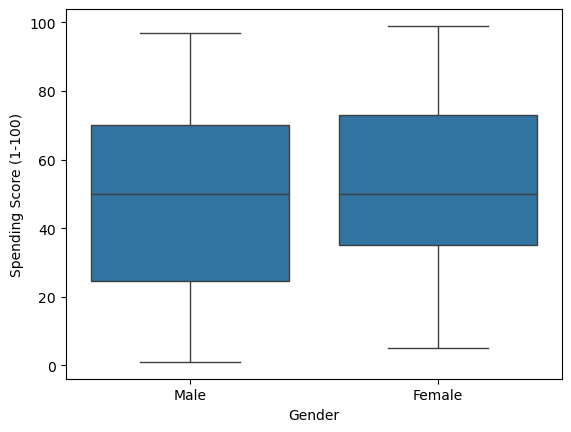

In [6]:
sns.boxplot(data=df,x="Gender", y="Spending Score (1-100)")

<Axes: xlabel='Annual Income (k$)', ylabel='Spending Score (1-100)'>

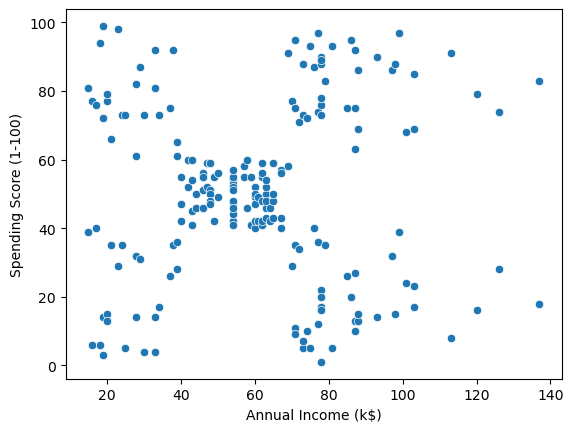

In [7]:
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)'
)

<Axes: xlabel='Age', ylabel='Spending Score (1-100)'>

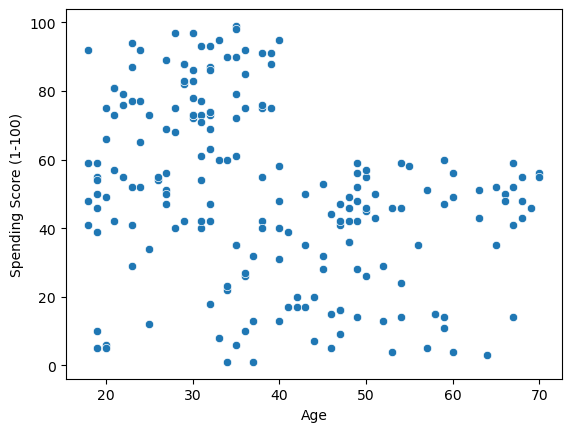

In [8]:
sns.scatterplot(
    data=df,
    x='Age',
    y='Spending Score (1-100)'
)

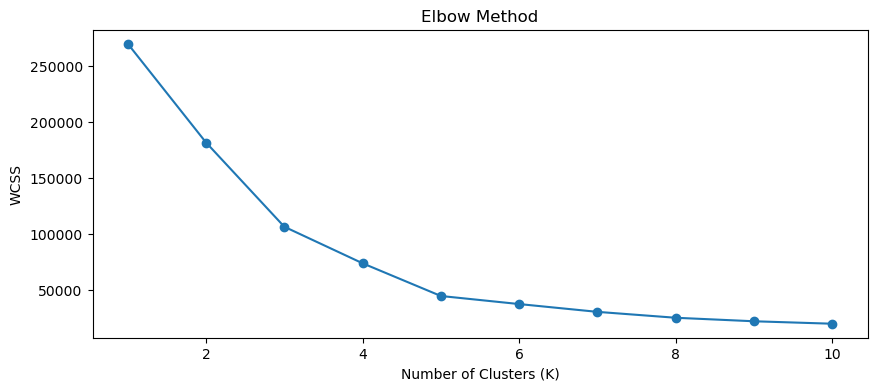

In [9]:
#Feature Selection
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

wcss=[]

for i in range(1,11):
    kmeans=KMeans(n_clusters=i, n_init=10)
    kmeans.fit(X)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10,4))
plt.plot(range(1,11),wcss,marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')

plt.show()

In [10]:
#Optimal K=5

kmeans=KMeans(n_clusters=5, n_init=10)
kmeans.fit(X)

#y_pred will have the cluster label 
y_pred=kmeans.predict(X)
y_pred

array([1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4,
       1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 0,
       1, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 3, 2, 0, 2, 3, 2, 3, 2,
       0, 2, 3, 2, 3, 2, 3, 2, 3, 2, 0, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2], dtype=int32)

In [11]:
df['Cluster'] = y_pred

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,1
1,2,Male,21,15,81,4
2,3,Female,20,16,6,1
3,4,Female,23,16,77,4
4,5,Female,31,17,40,1


In [12]:
centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=['Annual Income', 'Spending Score']
)

print(centroids)

   Annual Income  Spending Score
0      55.296296       49.518519
1      26.304348       20.913043
2      86.538462       82.128205
3      88.200000       17.114286
4      25.727273       79.363636


In [13]:
print(df['Cluster'].value_counts().sort_index())

Cluster
0    81
1    23
2    39
3    35
4    22
Name: count, dtype: int64


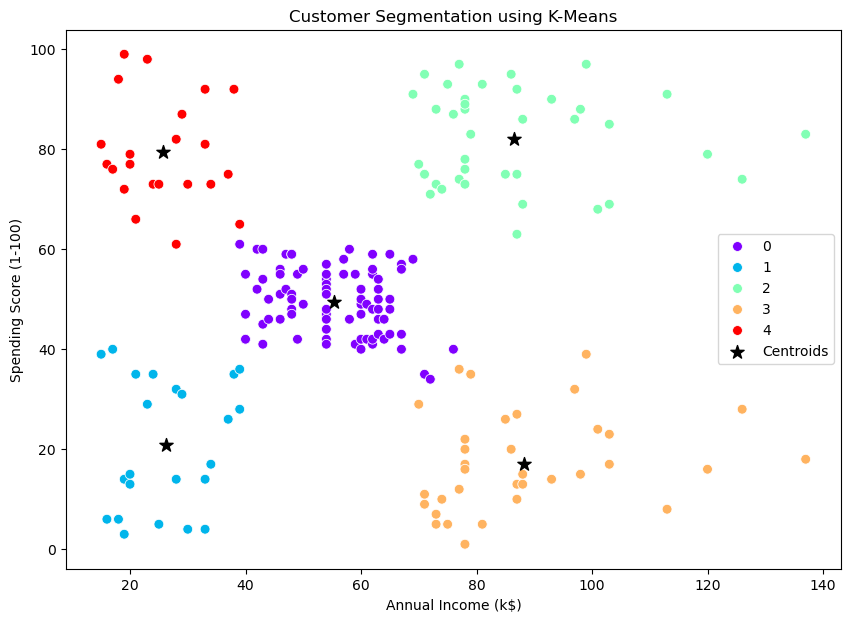

In [14]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    data=X,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue=y_pred,
    palette='rainbow',
    s=50
)


plt.scatter(
    data=centroids,
    x='Annual Income',
    y='Spending Score',
    color='black',
    marker='*',
    s=100,
    label='Centroids'
)

plt.scatter

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation using K-Means')

plt.legend()
plt.show()